# 04 - Cross-validation of Model E

The test set of notebook 03 holds only part of the molecules, drawn at random: its score depends a lot on that draw. Here, **every molecule is tested once**:
1. the molecules are split into 5 groups;
2. Model E is trained on 4 groups and tested on the 5th;
3. this is repeated with each group as the test group, and the whole procedure is repeated with several splits.

This gives a stable score, with its error margin, compared with simple rules on exactly the same molecules. The notebook uses all the molecules prepared by notebook 01 (train + test).

In [15]:
import sys
from pathlib import Path
# Find the project root (the folder that contains src/config.py) and make src/ importable
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from config import TRAIN, TEST, FIGURES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, balanced_accuracy_score

In [16]:
N_FOLDS = 5        # 5-fold cross-validation
N_REPEATS = 3      # number of different splits

In [17]:
# The 16 features of Model E: the order expected by scripts/predict.py
cols_E = ['MolWt', 'Sol_Dielectric', 'Sol_Hansen_D', 'Sol_Hansen_P', 'Sol_Hansen_H']
vector_cols = [f'Matrix_Vector_{i}' for i in range(1, 11)]
xgb_cols = ['RT'] + cols_E + vector_cols

def make_model_E(scale_weight):
    """Arthur's Model E: same settings as in rt_prediction_continued.ipynb (cell 18)."""
    return xgb.XGBClassifier(n_estimators=1000, learning_rate=0.01, max_depth=4, subsample=0.8,
        colsample_bytree=0.5,colsample_bynode=0.9, gamma=.8, min_child_weight=10, reg_lambda=5, reg_alpha=1,  scale_pos_weight=scale_weight,
        random_state=72, n_jobs=-1)

def rank_per_molecule(df, proba):
    """One row per molecule x solvent: mean predicted probability over the molecule's HPLC columns."""
    g = df[['SMILES', 'Solvent_Name', 'Soluble']].assign(proba=proba)
    return g.groupby(['SMILES', 'Solvent_Name'], as_index=False).agg(proba=('proba', 'mean'), Soluble=('Soluble', 'first'))

def first_choices(ranking):
    """For each molecule: the solvent ranked first, and whether that choice was right (the molecule dissolves in it)."""
    rows = []
    for smiles, g in ranking.groupby('SMILES'):
        best = g.loc[g['proba'].idxmax()]
        dmso = g[g['Solvent_Name'] == 'DMSO']
        rows.append({'SMILES': smiles, 'Solvent': best['Solvent_Name'], 'Correct': best['Soluble'] == 1,
                     'DMSO_correct': len(dmso) > 0 and dmso['Soluble'].iloc[0] == 1})
    return pd.DataFrame(rows)

In [18]:
df = pd.concat([pd.read_csv(TRAIN), pd.read_csv(TEST)], ignore_index=True)
X, y = df[xgb_cols], df['Soluble'].values
molecules = np.array(sorted(df['SMILES'].unique()))
print(f"{len(df)} rows, {len(molecules)} molecules")

5525 rows, 187 molecules


## Cross-validation

In [19]:
results, all_choices = [], []
for rep in range(N_REPEATS):
    mol_order = np.random.RandomState(rep).permutation(len(molecules))
    fold = pd.Series(np.arange(len(molecules)) % N_FOLDS, index=molecules[mol_order])
    for k in range(N_FOLDS):
        test_mol = set(fold[fold == k].index)
        te = df['SMILES'].isin(test_mol).values
        tr = ~te
        scale_weight = (tr.sum() - y[tr].sum()) / y[tr].sum()
        model_E = make_model_E(scale_weight).fit(X[tr], y[tr])

        proba = model_E.predict_proba(X[te])[:, 1]
        pred = (proba >= 0.5).astype(int)
        choices = first_choices(rank_per_molecule(df[te], proba))
        all_choices.append(choices)
        results.append({'split': rep + 1, 'fold': k + 1, 'molecules': len(test_mol),
                        'Accuracy': accuracy_score(y[te], pred),
                        'Precision': precision_score(y[te], pred, zero_division=0),
                        'Recall': recall_score(y[te], pred, zero_division=0),
                        'Balanced_accuracy': balanced_accuracy_score(y[te], pred),
                        'Top1': choices['Correct'].mean(),
                        'Ref_always_soluble': np.mean(y[te] == 1),
                        'Ref_always_DMSO': choices['DMSO_correct'].mean()})
        r = results[-1]
        print(f"split {rep + 1} fold {k + 1}: accuracy {r['Accuracy']:.3f} | top-1 {r['Top1']:.3f}")

results = pd.DataFrame(results)
all_choices = pd.concat(all_choices, ignore_index=True)

split 1 fold 1: accuracy 0.690 | top-1 0.816
split 1 fold 2: accuracy 0.612 | top-1 0.816
split 1 fold 3: accuracy 0.695 | top-1 0.838
split 1 fold 4: accuracy 0.706 | top-1 0.784
split 1 fold 5: accuracy 0.566 | top-1 0.811
split 2 fold 1: accuracy 0.692 | top-1 0.763
split 2 fold 2: accuracy 0.627 | top-1 0.816
split 2 fold 3: accuracy 0.641 | top-1 0.676
split 2 fold 4: accuracy 0.666 | top-1 0.838
split 2 fold 5: accuracy 0.687 | top-1 0.838
split 3 fold 1: accuracy 0.621 | top-1 0.895
split 3 fold 2: accuracy 0.642 | top-1 0.842
split 3 fold 3: accuracy 0.637 | top-1 0.703
split 3 fold 4: accuracy 0.692 | top-1 0.757
split 3 fold 5: accuracy 0.589 | top-1 0.757


## Summary

In [20]:
print("=== Summary (mean ± std) ===")
for col in ['Accuracy', 'Precision', 'Recall', 'Balanced_accuracy', 'Top1']:
    print(f"{col:18s}: {results[col].mean():.4f} ± {results[col].std():.4f}")
print("\n=== Compare with simple rules (same molecules) ===")
print(f"Accuracy when always answering 'soluble': {results['Ref_always_soluble'].mean():.4f}")
print(f"Balanced accuracy of random guessing:     0.5000")
print(f"Top-1 when always suggesting DMSO:        {results['Ref_always_DMSO'].mean():.4f}")

=== Summary (mean ± std) ===
Accuracy          : 0.6508 ± 0.0430
Precision         : 0.7748 ± 0.0378
Recall            : 0.6952 ± 0.0526
Balanced_accuracy : 0.6217 ± 0.0489
Top1              : 0.7965 ± 0.0573

=== Compare with simple rules (same molecules) ===
Accuracy when always answering 'soluble': 0.6892
Balanced accuracy of random guessing:     0.5000
Top-1 when always suggesting DMSO:        0.7322


## Which solvent does the model suggest first?

Over all molecules and all splits: in what percentage of cases each solvent is suggested first, and how often that choice was right.

,% of cases,Correct (%)
Solvent,,
MeOH,0.9,40.0
ACN,0.0,NaN
DMSO,51.5,76.5
DCM,3.6,80.0
CHCl3,44.0,84.2


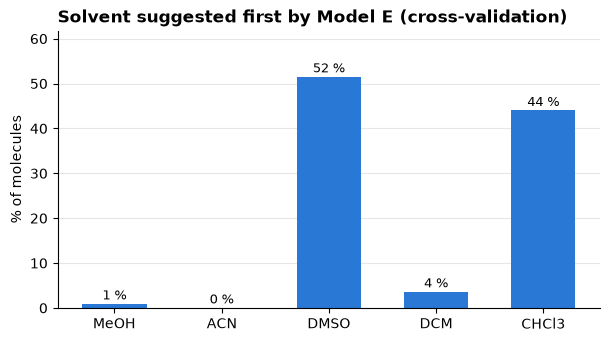

In [21]:
order = ['MeOH', 'ACN', 'DMSO', 'DCM', 'CHCl3']
distribution = pd.DataFrame({
    '% of cases': (all_choices['Solvent'].value_counts(normalize=True) * 100).reindex(order, fill_value=0).round(1),
    'Correct (%)': (all_choices.groupby('Solvent')['Correct'].mean() * 100).reindex(order).round(1),
})
display(distribution)

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(order, distribution['% of cases'], color='#2a78d6', width=0.6)
for b, v in zip(bars, distribution['% of cases']):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f} %", ha='center', fontsize=9)
ax.set_ylabel("% of molecules"); ax.set_ylim(0, distribution['% of cases'].max() * 1.18 + 1)
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#e6e6e3'); ax.set_axisbelow(True)
ax.set_title("Solvent suggested first by Model E (cross-validation)", loc='left', fontweight='bold')
out = FIGURES / "experiments" / "top1_solvent_distribution.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=200, bbox_inches='tight')
plt.show()